**Exercise Overview**
Train and evaluate different MLP and CNN for classificating clothing items with different learning rates and batch sizes

## Q12 - NN

### c

_Training and Evaluation including over/underfitting_

*Training Process*
- Data preparation:
	- Split into training, validation, and test sets.
- Model training:
	- Train NN models by minimizing their loss function 
	- Here optimized using **Stochastic Gradient Descent** with momentum
Evaluation:
- Evaluate model performance on validation and test sets using metrics like 
	- Accuracy
	- Precision
	- Recall.
- Evaluate the performance across different **hyperparameters** to find best
	- Learning rate:
		- Lower learning rate → Better performance but slower convergence.
		- Higher learning rate → Faster convergence but may cause instability.
	- Batch size:
		- Small batch sizes → Improve generalization but increase training time.
		- Large batch sizes → Faster training but risk poor generalization.

**Signs of overfitting and underfitting**
- Overfitting:
	- **Variance:** High accuracy on training data but poor performance on validation/test sets.
	- Model learns noise and irrelevant patterns in the training data.
	- **Solutions:**
		- Use regularization (L1/L2).
		- Early dropout
		- Early stopping to prevent overtraining.
- Underfitting:
	- Poor accuracy on both training and validation/test sets.
	- **Bias:** Model is too simple or not trained long enough.
	- Solutions:
		- Increase model complexity (add layers/neurons).
		- Train for more epochs.
		- Adjust learning rate or optimizer


### d

**Fully Connected Networks (MLP)**
- Consists of layers where **every neuron is connected to every neuron** in the previous and next layer 
- Many model parameters

**Problem** 
- For high dimensional data **images** MLP gets a lot of model parameters
	- **Overfitting:** The model memorizes training data rather than generalizing.
	- **Inefficiency:** Requires high computational power and memory.

**Convolutional Neural Networks**
- Breaking the task into smaller sub-problems (e.g., detecting edges, combining shapes).
- Convolutes filters on the data. Model parameters for a filter is **shared** for all of the input
- **Architecture**
	- Input Layer: Receives data (e.g., images).
	- Convolutional Layer: Applies filters to learn local patterns (e.g., edges, textures).
	- Pooling Layer: Reduce dimension by only saving the most significant info
	- Flattening
	- Fully Connected Layer: Combines all extracted features
	- Output Layer: Outputs the final result (e.g., class).
- "This image has whiskers, pointy ears, and a round face" → Likely a cat.

# Neural network architectures
This exercise focuses on the classification of the FashionMNIST dataset using two types of neural network architectures: the Multi-Layer Perceptron (MLP) and the Convolutional Neural Network (CNN). The performance of these models will be assessed using the evaluation metrics introduced in earlier exercises.

<article class="message">
    <div class="message-body">
        <strong>List of individual tasks</strong>
        <ul style="list-style: none;">
            <li>
            <a href="#MLP1">Task 1: Training basic MLP</a>
            </li>
            <li>
            <a href="#MLP3">Task 2: Evaluation</a>
            </li>
            <li>
            <a href="#MLP33">Task 3: Training basic MLP modifying hyperparame…</a>
            </li>
            <li>
            <a href="#MLP33333">Task 4: Comparison</a>
            </li>
            <li>
            <a href="#CNN1">Task 5: CNN architecture</a>
            </li>
            <li>
            <a href="#CNN11">Task 6: Training a basic CNN</a>
            </li>
            <li>
            <a href="#CNN21">Task 7: Evaluation</a>
            </li>
            <li>
            <a href="#CNN211">Task 8: Training a basic CNN modifying hyperpara…</a>
            </li>
            <li>
            <a href="#CNN3">Task 9: Evaluation</a>
            </li>
            <li>
            <a href="#CNN311">Task 10: Evaluation</a>
            </li>
            <li>
            <a href="#modifications">Task 11: Adding a hidden layer</a>
            </li>
            <li>
            <a href="#CNN20101">Task 12: Compare performance</a>
            </li>
            <li>
            <a href="#CNN_mod">Task 13: Compare architectures</a>
            </li>
            <li>
            <a href="#CNN233">Task 14: Compare performance</a>
            </li>
            <li>
            <a href="#CNN2123">Task 15: Update architecture</a>
            </li>
            <li>
            <a href="#modifications3">Task 16: Adding a convolutional layer</a>
            </li>
            <li>
            <a href="#CNN003">Task 17: Compare architectures</a>
            </li>
            <li>
            <a href="#modifications4">Task 18: Compare architectures</a>
            </li>
            <li>
            <a href="#additional">Task 19: Additional improvements</a>
            </li>
        </ul>
    </div>
</article>


**Time sink warning**
This exercise examines the impact of network architectures and hyperparameters on training and performance. **Notice getting optimal results can become a time sink. Make well-argued choices as endless options and combinations are available.** Focus on informed decisions given the vast number of options available. Most of the code is provided requiring only modifications to hyperparameter settings and network architecture. This setup allows for focused analysis of outcomes and their connection to theoretical concepts.

## Modifying hyperparameters
This part of the exercise introduces and experiments with the hyperparameters of an NN such as the _Learning rate_ and the _batch size_. 
### Multilayer Perceptron
The following tasks are about training and modifying an MLP to classify the FashionMNIST dataset. The following functions will be used throughout the exercise:
- `train_pytorch_network`
: takes an NN class as a parameter. Used for model training and for visualizing the performance of the models throughout the exercise. 
- `evaluate_overall_metrics`
 in the `cnn_util.py`
 file takes a dictionary containing a key-value pair of a name and a file path to the trained model and a list with the class names. The function returns a plot showing the overall _accuracy_, _precision_ and _recall_ for the validation data, comparing each model trained. 
- `evaluate`
 in the `cnn_util.py`
 file takes a dictionary containing a key-value pair of a name and a file path to the trained model and a list with the class names. The function computes a confusion matrix as well as provides plots visualizing _Accuracy_, _Precision_ and _Recall_ class-wise for the validation data, comparing each model trained. 


---
**Task 1 (easy): Training basic MLP👩‍💻💡**
1. Examine the `networks.py`
 file and locate the `MLPBasic()`
 class. Examine the class to gain an overview of the network architecture.
2. Run the cell below to train the MLP. The cell will automatically save the trained model in the `models/`
 directory.


---

In [20]:
from torch import optim
from trainers import PyTorchTrainer
from networks import *
from torchvision import transforms
from cnn_util import *
from fashionmnist_utils.mnist_reader import load_mnist

# uncomment if not first run
from models import *

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create the 'models' folder
os.makedirs("models", exist_ok=True)
# Create the 'runs' folder
os.makedirs("runs", exist_ok=True) 


def train_pytorch_network(to_train):

    transform = transforms.ToTensor() ## conversion from PIL image format to torch tensors.

    network = to_train

    trainerNetwork = PyTorchTrainer(
        nn_module=network,
        transform=transform,
        optimizer=optim.SGD(network.parameters(), lr=1e-2, momentum=0.5), # Stochastic Gradient Descent
        batch_size=128                                                    # batch size         
    ) 

    print("training the network started")
    classes = ['t-shirt','trouser','pullover','dress','coat','sandal','shirt','sneaker','bag','ankle boot']
    trainerNetwork.train(10)
    trainerNetwork.plot_metrics(classes)


    # Evaluate the model
    logger, predictions = trainerNetwork.evaluate()
    trainerNetwork.save()
    print("training and saving the network ended")


training the network started
[Epoch 1]


100%|██████████| 94/94 [00:00<00:00, 294.54it/s]


[Validation] Epoch 1: acc: 0.4333, val_loss: 2.2350, train_acc: 0.3181
[Epoch 2]


100%|██████████| 94/94 [00:00<00:00, 313.42it/s]


[Validation] Epoch 2: acc: 0.5572, val_loss: 2.0266, train_acc: 0.3891
[Epoch 3]


100%|██████████| 94/94 [00:00<00:00, 303.82it/s]


... (11 outputs left out)

100%|██████████| 94/94 [00:00<00:00, 309.67it/s]


[Validation] Epoch 9: acc: 0.7210, val_loss: 1.7676, train_acc: 0.5967
[Epoch 10]


100%|██████████| 94/94 [00:00<00:00, 301.84it/s]


[Validation] Epoch 10: acc: 0.7460, val_loss: 1.7546, train_acc: 0.6092


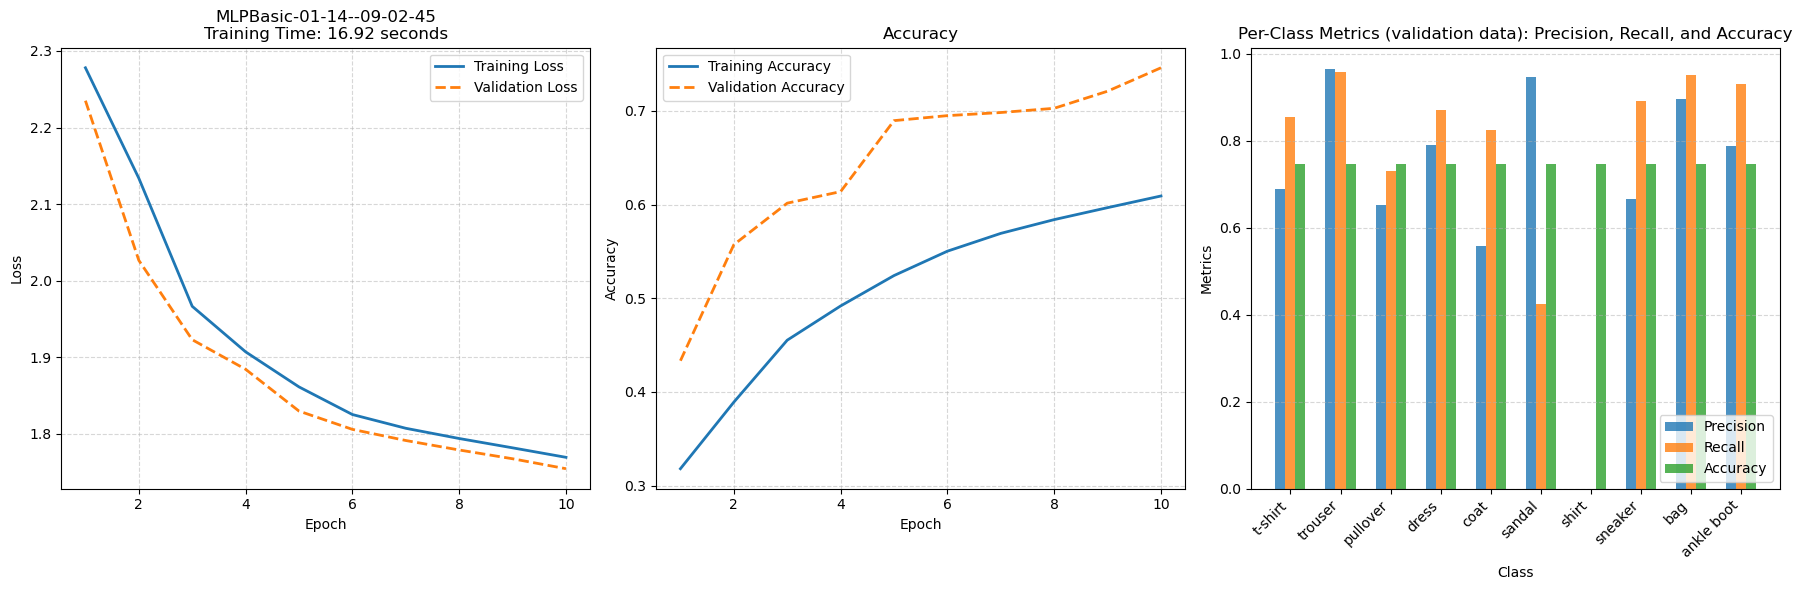

100%|██████████| 79/79 [00:00<00:00, 293.75it/s]

training and saving the network ended


In [21]:
train_pytorch_network(MLPBasic()) 


---
**Task 2 (easy): Evaluation💡**
1. Evaluate the performance of the model during training:    - Inspect the accuracy, loss and training time. What patterns or trends do you observe in the loss and accuracy graphs throughout training?




---

In [22]:
# Traing time: 18 seconds
# Loss. Starts high, decreases quickly. Also low on validation set. Consistent learning
# Accuracy: Starts low, increases quicly. High on validation set. Consistent learning and good generalization
# The model is not overfitting, as the validation accuracy is higher than the training accuracy.
# Performance is lower for more challenging classes like "shirt," which may have more overlap with other classes (e.g., "t-shirt" or "coat").
# Maybe struggles to distinguish between similar classes like "t-shirt" and "shirt" and "pullover"

"""
Precision measures the proportion of correctly predicted positive instances out of all instances predicted as positive.
Recall (or Sensitivity) measures the proportion of correctly predicted positive instances out of all actual positive instances.
Accuracy measures the proportion of all correct predictions (both positive and negative) out of the total predictions.
"""

'\nPrecision measures the proportion of correctly predicted positive instances out of all instances predicted as positive.\nRecall (or Sensitivity) measures the proportion of correctly predicted positive instances out of all actual positive instances.\nAccuracy measures the proportion of all correct predictions (both positive and negative) out of the total predictions.\n'

The next task experiments with different hyperparameters. Use the function`evaluate_overall_metrics`
 to visualize and compare the overall performance of the models and use the `evaluate`
 function to visualise and compare the performance of the models class-wise. [Figure 1](#ex) provides an example of the type of plots returned by the functions.
<div style="float: none; width: 100%; justify-content: start" class="block is-clearfix">

<div style="float: left; width: 50%; justify-content: start" class="block is-clearfix">

<div class="has-text-centered">
<figure class="image is-inline-block" id="ex">

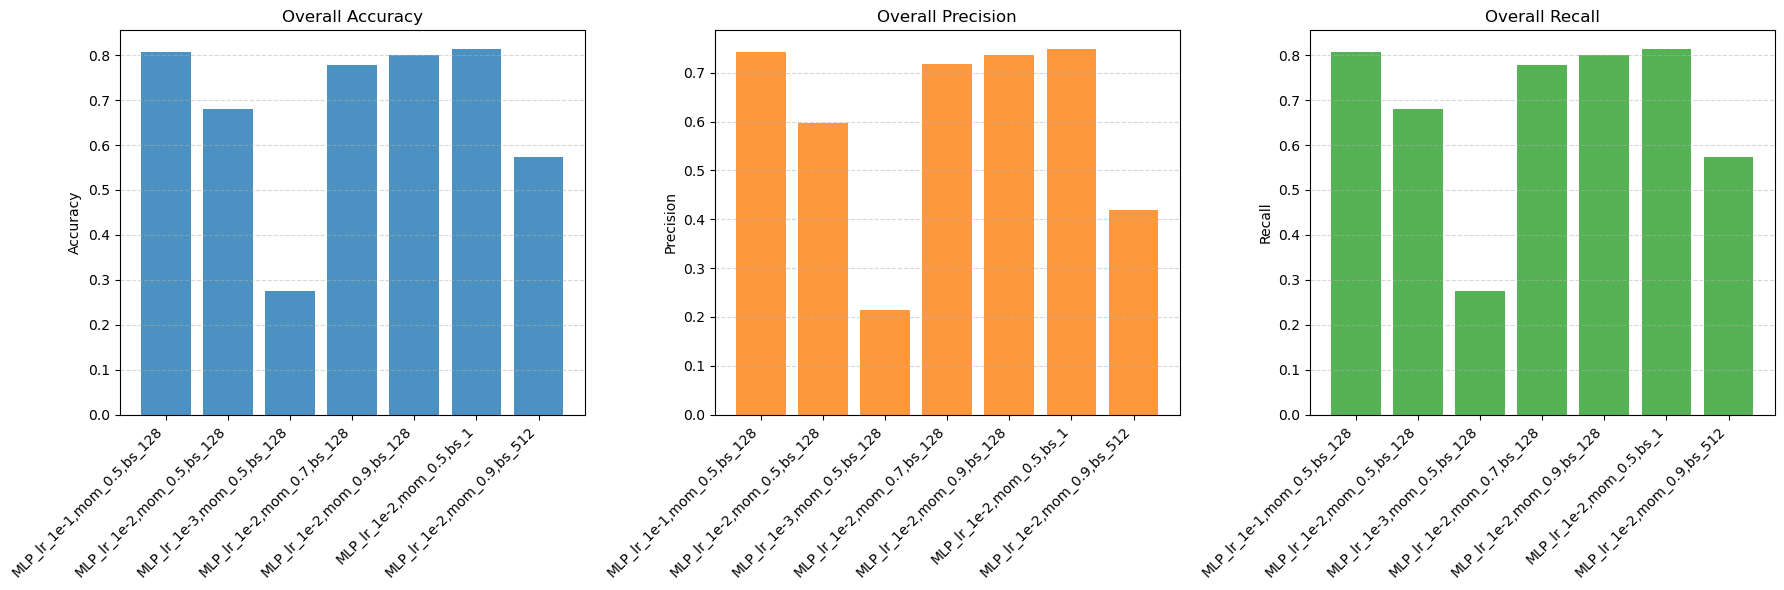

<figcaption class="figure-caption has-text-center">Figure 1: Example of output from the `evaluate_overall_metrics`
 function.
</figcaption>
</figure>
</div>


</div>

<div style="float: right; width: 50%; justify-content: start" class="block is-clearfix">

<div class="has-text-centered">
<figure class="image is-inline-block" id="model">

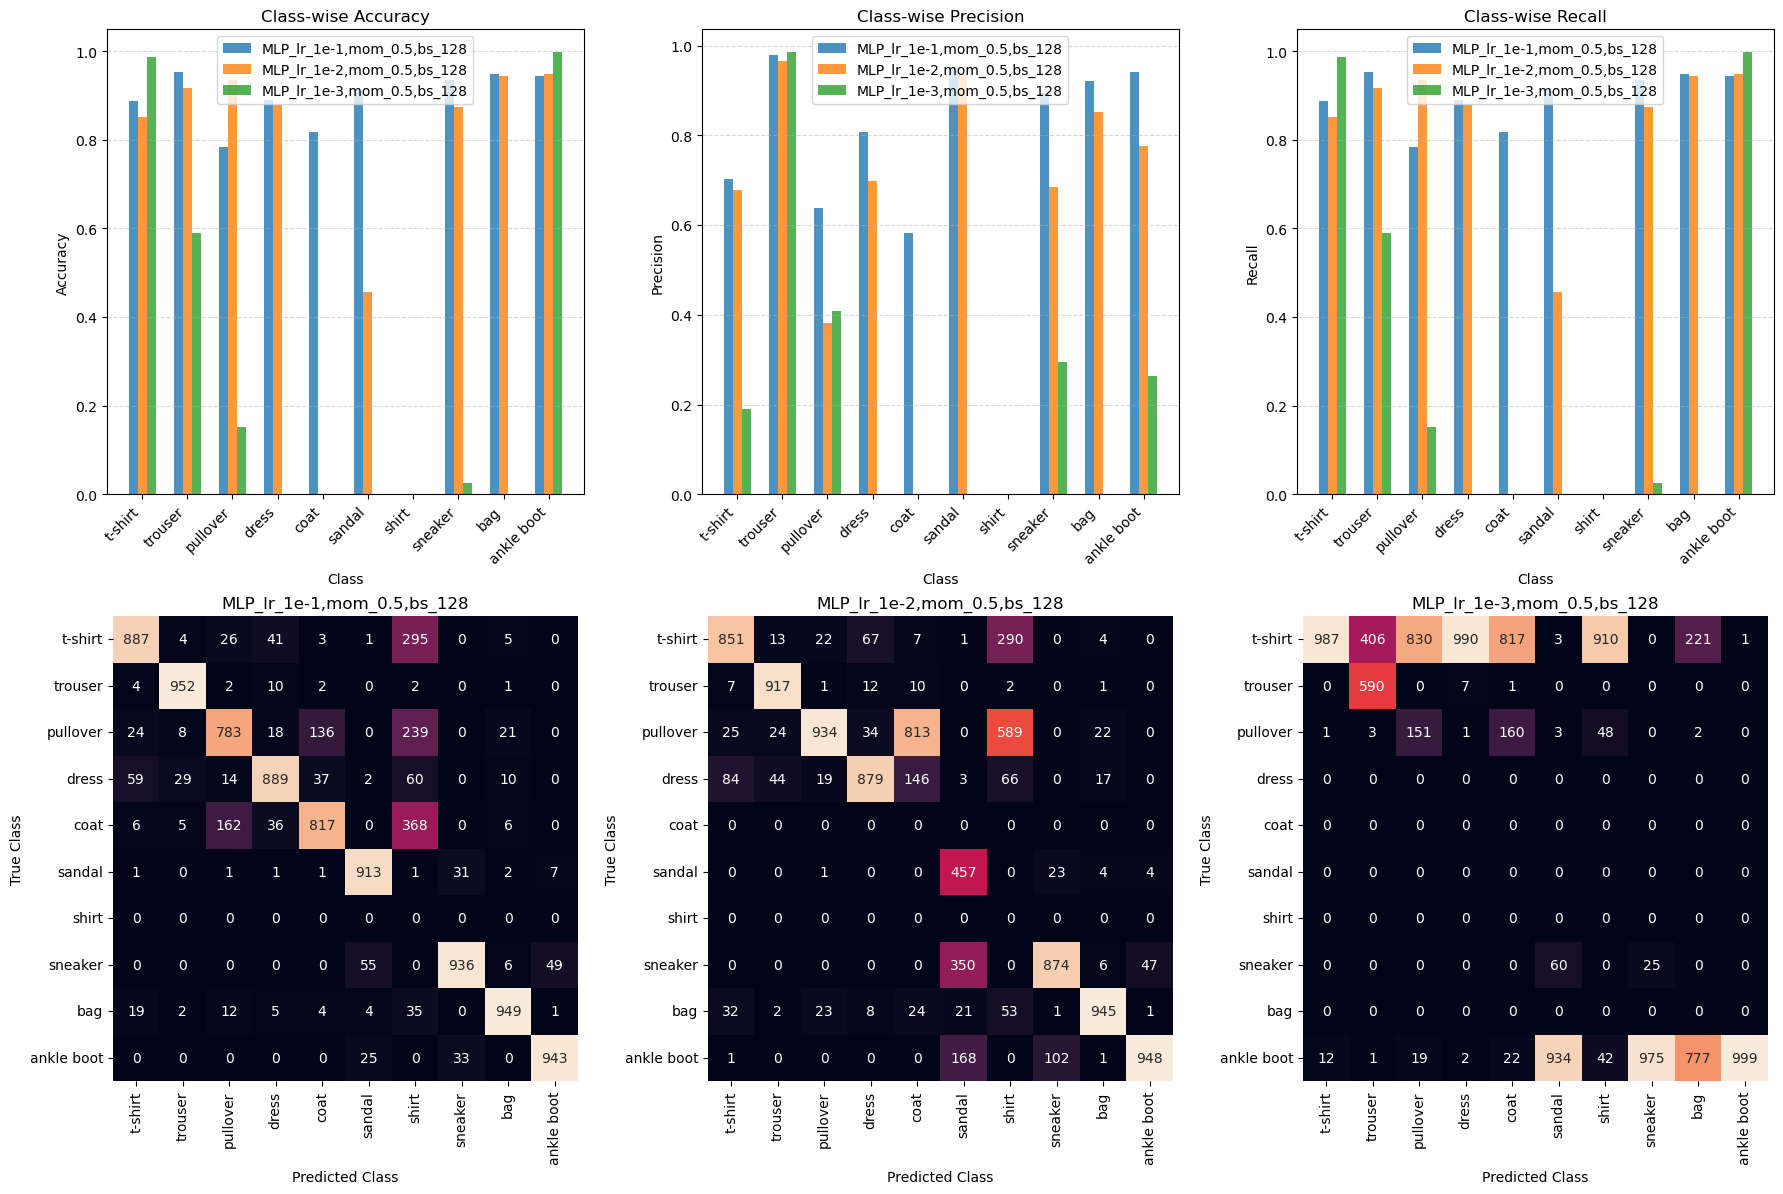

<figcaption class="figure-caption has-text-center">Figure 2: Example of output from the `evaluate`
 function.
</figcaption>
</figure>
</div>


</div>



</div>


---
**Task 3 (easy): Training basic MLP modifying hyperparameters👩‍💻**
1. Explore how different hyperparameters influence the training and performance of the model:
    - Modify training variables and train new models:        
        - Set the learning rate to 1e-3, and 1e-1. 
        - Reset the learning rate to 1e-2 then modify the batch size to 1 and 512. 
    - Fill the dictionaries below with the paths of the trained models.
    - Visualize the overall metrics of performance for all models trained using the `evaluate_overall_metrics` function.
    - Visualize the performance by running the `evaluate`
 function.


**Hint**
The cell below is a guide for how to load the models after training. The models are located in the `models`
 folder.




---

100%|██████████| 20/20 [00:00<00:00, 78.25it/s]


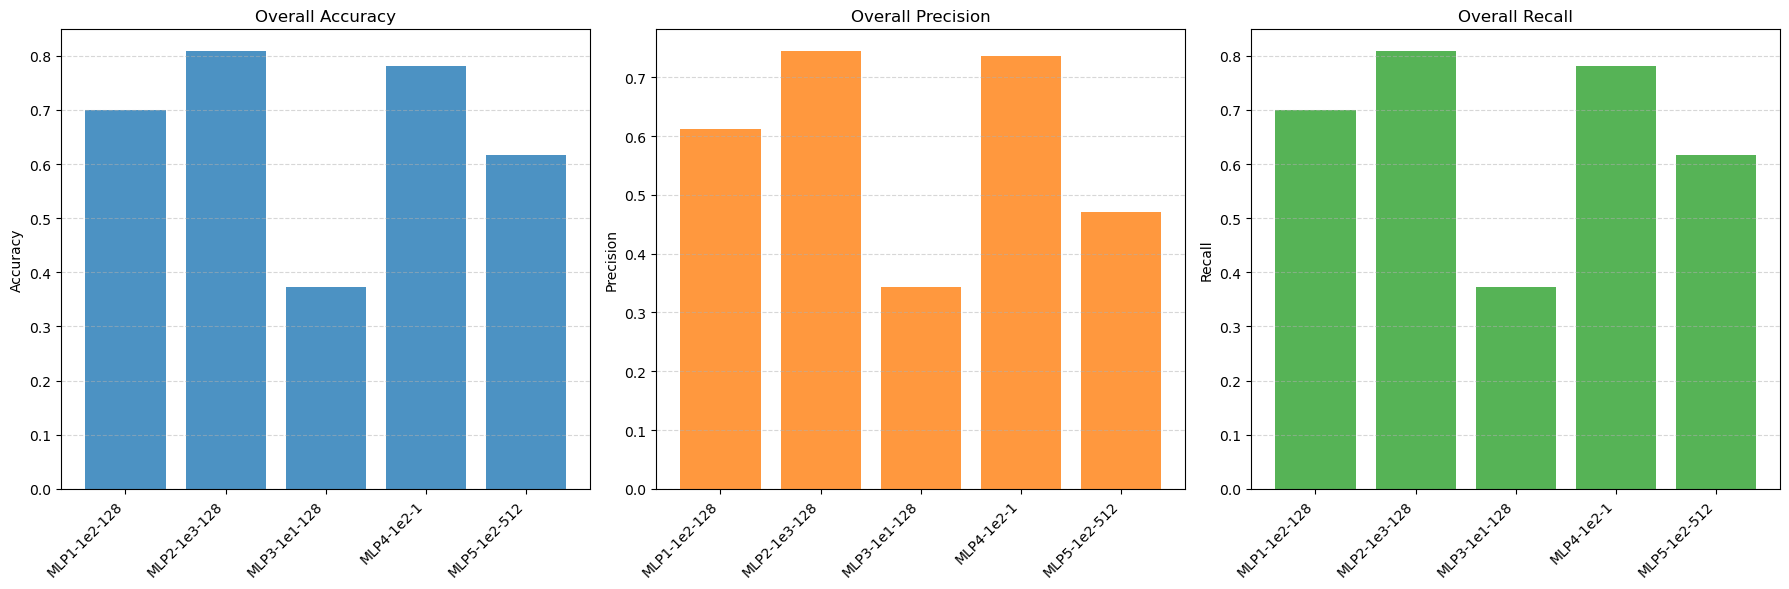

100%|██████████| 20/20 [00:00<00:00, 61.82it/s]


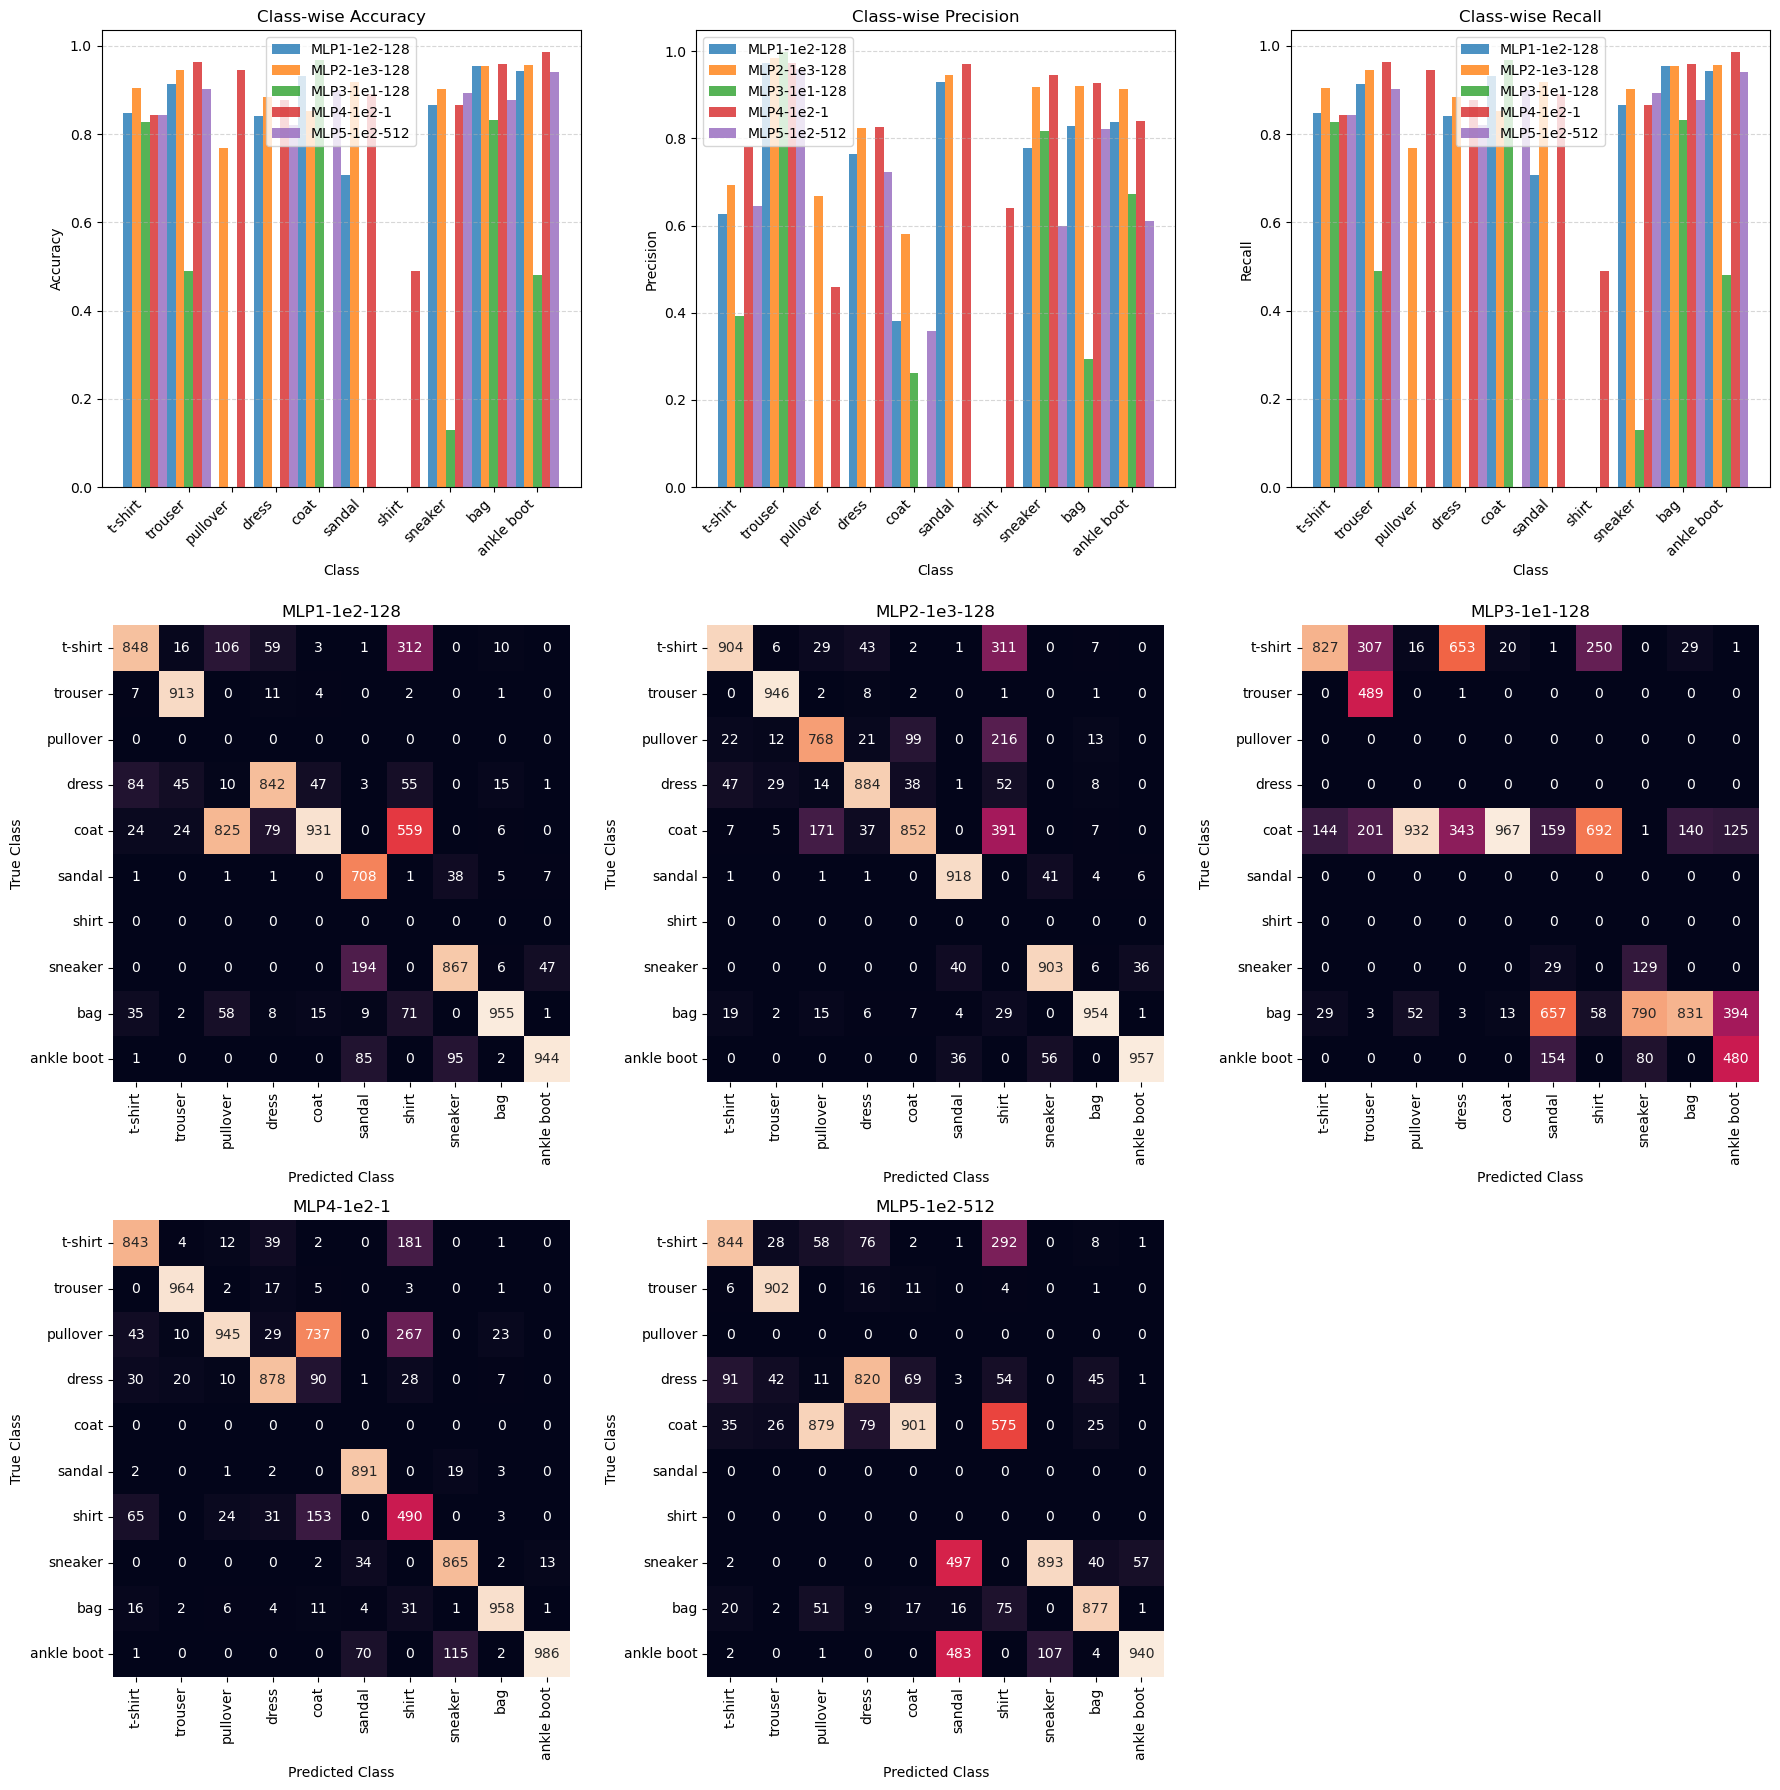

In [23]:

from math import e


MLP_models = {
    'MLP1-1e2-128': PyTorchTrainer.load('models/MLPBasic1.pkl'),
    'MLP2-1e3-128': PyTorchTrainer.load('models/MLPBasic2.pkl'),
    'MLP3-1e1-128': PyTorchTrainer.load('models/MLPBasic3.pkl'),
    'MLP4-1e2-1':   PyTorchTrainer.load('models/MLPBasic4.pkl'),
    'MLP5-1e2-512': PyTorchTrainer.load('models/MLPBasic5.pkl'),
    # Add more...
    }

# Visualize the performance of the models
evaluate_overall_metrics(MLP_models)
evaluate(MLP_models)


---
**Task 4 (easy): Comparison💡**
1. Compare the performance of the models:    - Evaluate the models using accuracy, precision, recall, and heatmaps.
    - Discuss how the changes in hyperparameters, such as learning rate and batch size, influence these performance metrics. Highlight any trends or trade-offs observed, such as improvements in accuracy versus potential declines in precision or recall.


2. How is the training time affected by the different hyperparameters?


---

In [24]:
"""
1. Evaluation of Metrics
Overall Accuracy:
MLP1 (LR=1e-2, Batch=128): Baseline accuracy is moderate.
MLP2 (LR=1e-3, Batch=128): Lower learning rate improves stability, leading to better accuracy.
MLP3 (LR=1e-1, Batch=128): Higher learning rate causes overshooting, resulting in reduced accuracy.
MLP4 (LR=1e-2, Batch=1): Small batch size improves learning for noisier patterns but introduces noise in gradient updates, leading to moderate accuracy.
MLP5 (LR=1e-2, Batch=512): Large batch size reduces gradient noise but may not generalize well, leading to slightly lower accuracy.

Overall Precision and Recall:
Precision and recall trends align with accuracy
MLP2 (LR=1e-3) performs better due to smaller steps, which help refine weight updates.
MLP3 (LR=1e-1) shows lower precision and recall due to overshooting during training.
MLP5 (Batch=512) has reduced precision and recall, possibly due to over-reliance on large batch gradients.

Class-Wise Metrics:
Certain classes (e.g., "ankle boot," "bag") consistently achieve higher metrics, indicating they are easier to classify.
Challenging classes (e.g., "shirt", "coat") show lower metrics across models, likely due to visual similarity with other classes
MLP3 (high learning rate) shows more confusion between similar classes, such as "shirt" and "coat."
"""

"""
2. Hyperparameter Influence

Learning Rate:
Low Learning Rate (1e-3):
Improves stability and allows the model to converge more effectively, leading to better accuracy, precision, and recall.
Slower convergence increases training time.
High Learning Rate (1e-1):
Faster convergence initially but risks overshooting and unstable learning, resulting in reduced metrics.
Training is faster but less effective.

Batch Size:
Small Batch Size (1):
Improves the model's ability to learn finer patterns due to noisier gradient updates.
Leads to higher variability in training, with moderate metrics and longer training time.
Large Batch Size (512):
Smooth gradients improve stability, but reduced gradient variability may hurt generalization.
Training is faster due to fewer gradient updates.
Small Batch Size: Longer training time due to more updates required per epoch.
Large Batch Size: Faster training but reduced generalization.
"""

"""
Key Takeaways
Trade-offs:
Lower learning rates and small batch sizes improve metrics but increase training time.
Higher learning rates and large batch sizes reduce training time but may hurt model performance.

Best Performance:
MLP2 (LR=1e-3, Batch=128) low learning rate, semi batch. achieves the best balance between accuracy, precision, recall, and training time.
"""

'\nKey Takeaways\nTrade-offs:\nLower learning rates and small batch sizes improve metrics but increase training time.\nHigher learning rates and large batch sizes reduce training time but may hurt model performance.\n\nBest Performance:\nMLP2 (LR=1e-3, Batch=128) low learning rate, semi batch. achieves the best balance between accuracy, precision, recall, and training time.\n'

### Convolutional Neural Network
The following tasks investigate a CNN architecture for the same problem.

---
**Task 5 (easy): CNN architecture💡**
1. Locate the `CNNBasic`
 model defined in `networks.py`
 and explain the architecture.


---

In [25]:
# Input layer: 784 neurons (28x28 pixels)
# Convulutional Layer 1: 8 filters of size 9 x 9, outputs 8 feature maps of size 20 x 20
# ReLU Activation
# Max Pooling Layer 1: 2 x 2 pooling, outputs 8 feature maps of size 10 x 10
# Convulutional Layer 2: 16 filters of size 3 x 3, outputs 16 feature maps of size 8 x 8
# ReLU Activation
# Max Pooling Layer 2: 2 x 2 pooling, outputs 16 feature maps of size 4 x 4
# Flattening into a 256-neuron layer
# First fully connected layer: 256 neurons -> 60 neurons
# ReLU Activation
# Second fully connected layer: 60 neurons -> 10 neurons (classes)


---
**Task 6 (easy): Training a basic CNN👩‍💻**
1. Run the cell below to train the `CNNBasic`
 model.


---

training the network started
[Epoch 1]


100%|██████████| 94/94 [00:00<00:00, 153.03it/s]


[Validation] Epoch 1: acc: 0.5962, val_loss: 1.0732, train_acc: 0.2849
[Epoch 2]


100%|██████████| 94/94 [00:00<00:00, 170.17it/s]


[Validation] Epoch 2: acc: 0.7188, val_loss: 0.7548, train_acc: 0.4763
[Epoch 3]


100%|██████████| 94/94 [00:00<00:00, 144.61it/s]


... (11 outputs left out)

100%|██████████| 94/94 [00:00<00:00, 145.31it/s]


[Validation] Epoch 9: acc: 0.8177, val_loss: 0.4949, train_acc: 0.7082
[Epoch 10]


100%|██████████| 94/94 [00:00<00:00, 156.08it/s]


[Validation] Epoch 10: acc: 0.8273, val_loss: 0.4815, train_acc: 0.7195


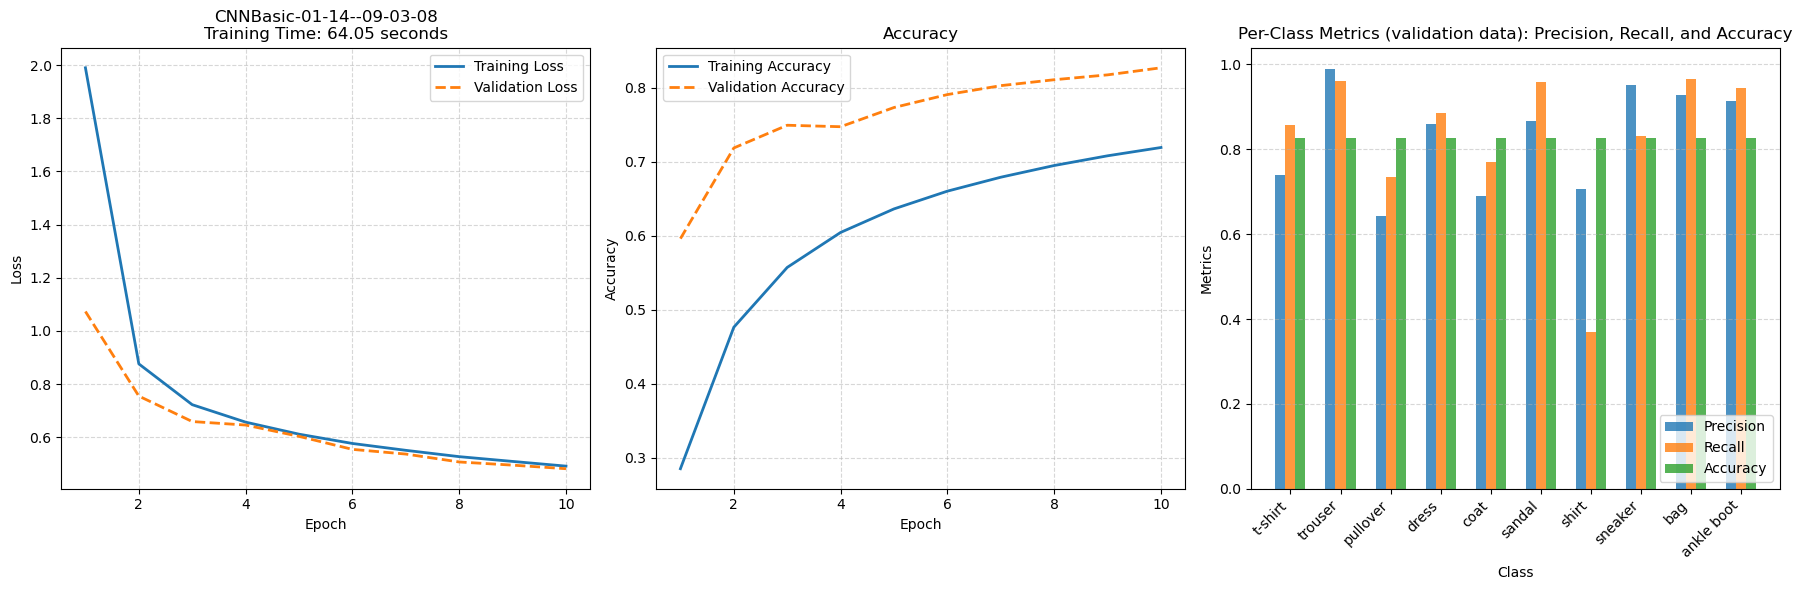

100%|██████████| 79/79 [00:00<00:00, 143.87it/s]

training and saving the network ended


In [26]:
train_pytorch_network(CNNBasic())


---
**Task 7 (easy): Evaluation👩‍💻💡**
1. Analyze the training figures and describe the key characteristics of the model’s training process.


---

In [27]:
# Both training and validation loss decrease rapidly within the first few epochs (2–3), indicating effective learning at the start.
# The training and validation loss curves are closely aligned, suggesting that the model generalizes well to unseen data.
# The CNN's convolutional layers effectively extract spatial features, leading to better performance compared to the MLP.
# Better than MLP to distinguish between similar classes like "shirt" and "coat" due to spatial feature extraction.
# But still struggles with challenging classes like "shirt" and "pullover" due to visual similarity.
# Longer training time due to convolutional layers and pooling operations, but better performance and generalization.


---
**Task 8 (easy): Training a basic CNN modifying hyperparameters👩‍💻💡**
1. Experiment with the different hyperparameters affecting the training and performance of the model.    
- Modify the following hyperparameters and train new model:        
   - Set the learning rate to 1e-4, and 1e-5. 
   - Modify the batch size to 256 and 1024. 


    - Fill the dictionary below with the paths of the trained models.
    - Visualize the overall performance by running `evaluate_overall_metrics`
 function.
    - Visualize the class-wise performance by running the `evaluate`
 function.




---

100%|██████████| 10/10 [00:00<00:00, 17.80it/s]


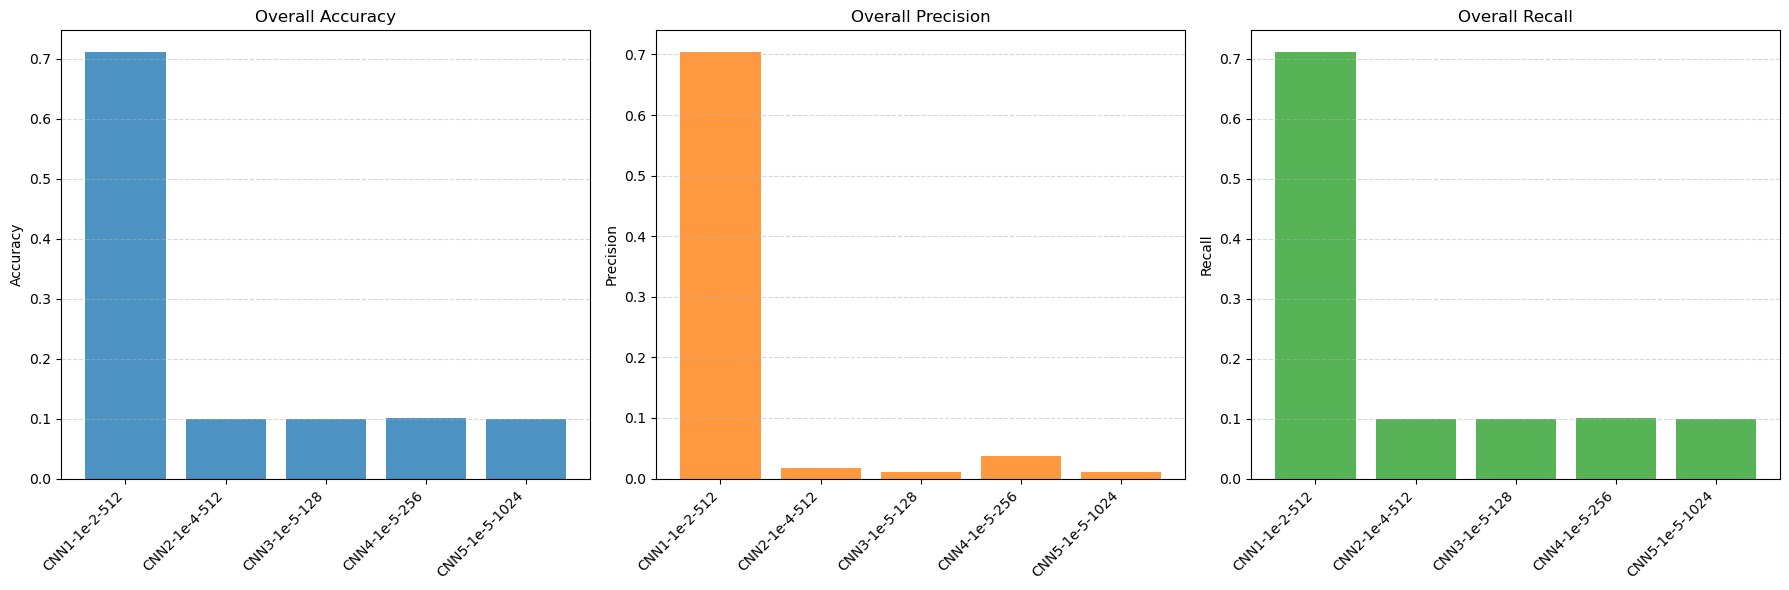

100%|██████████| 10/10 [00:00<00:00, 19.51it/s]


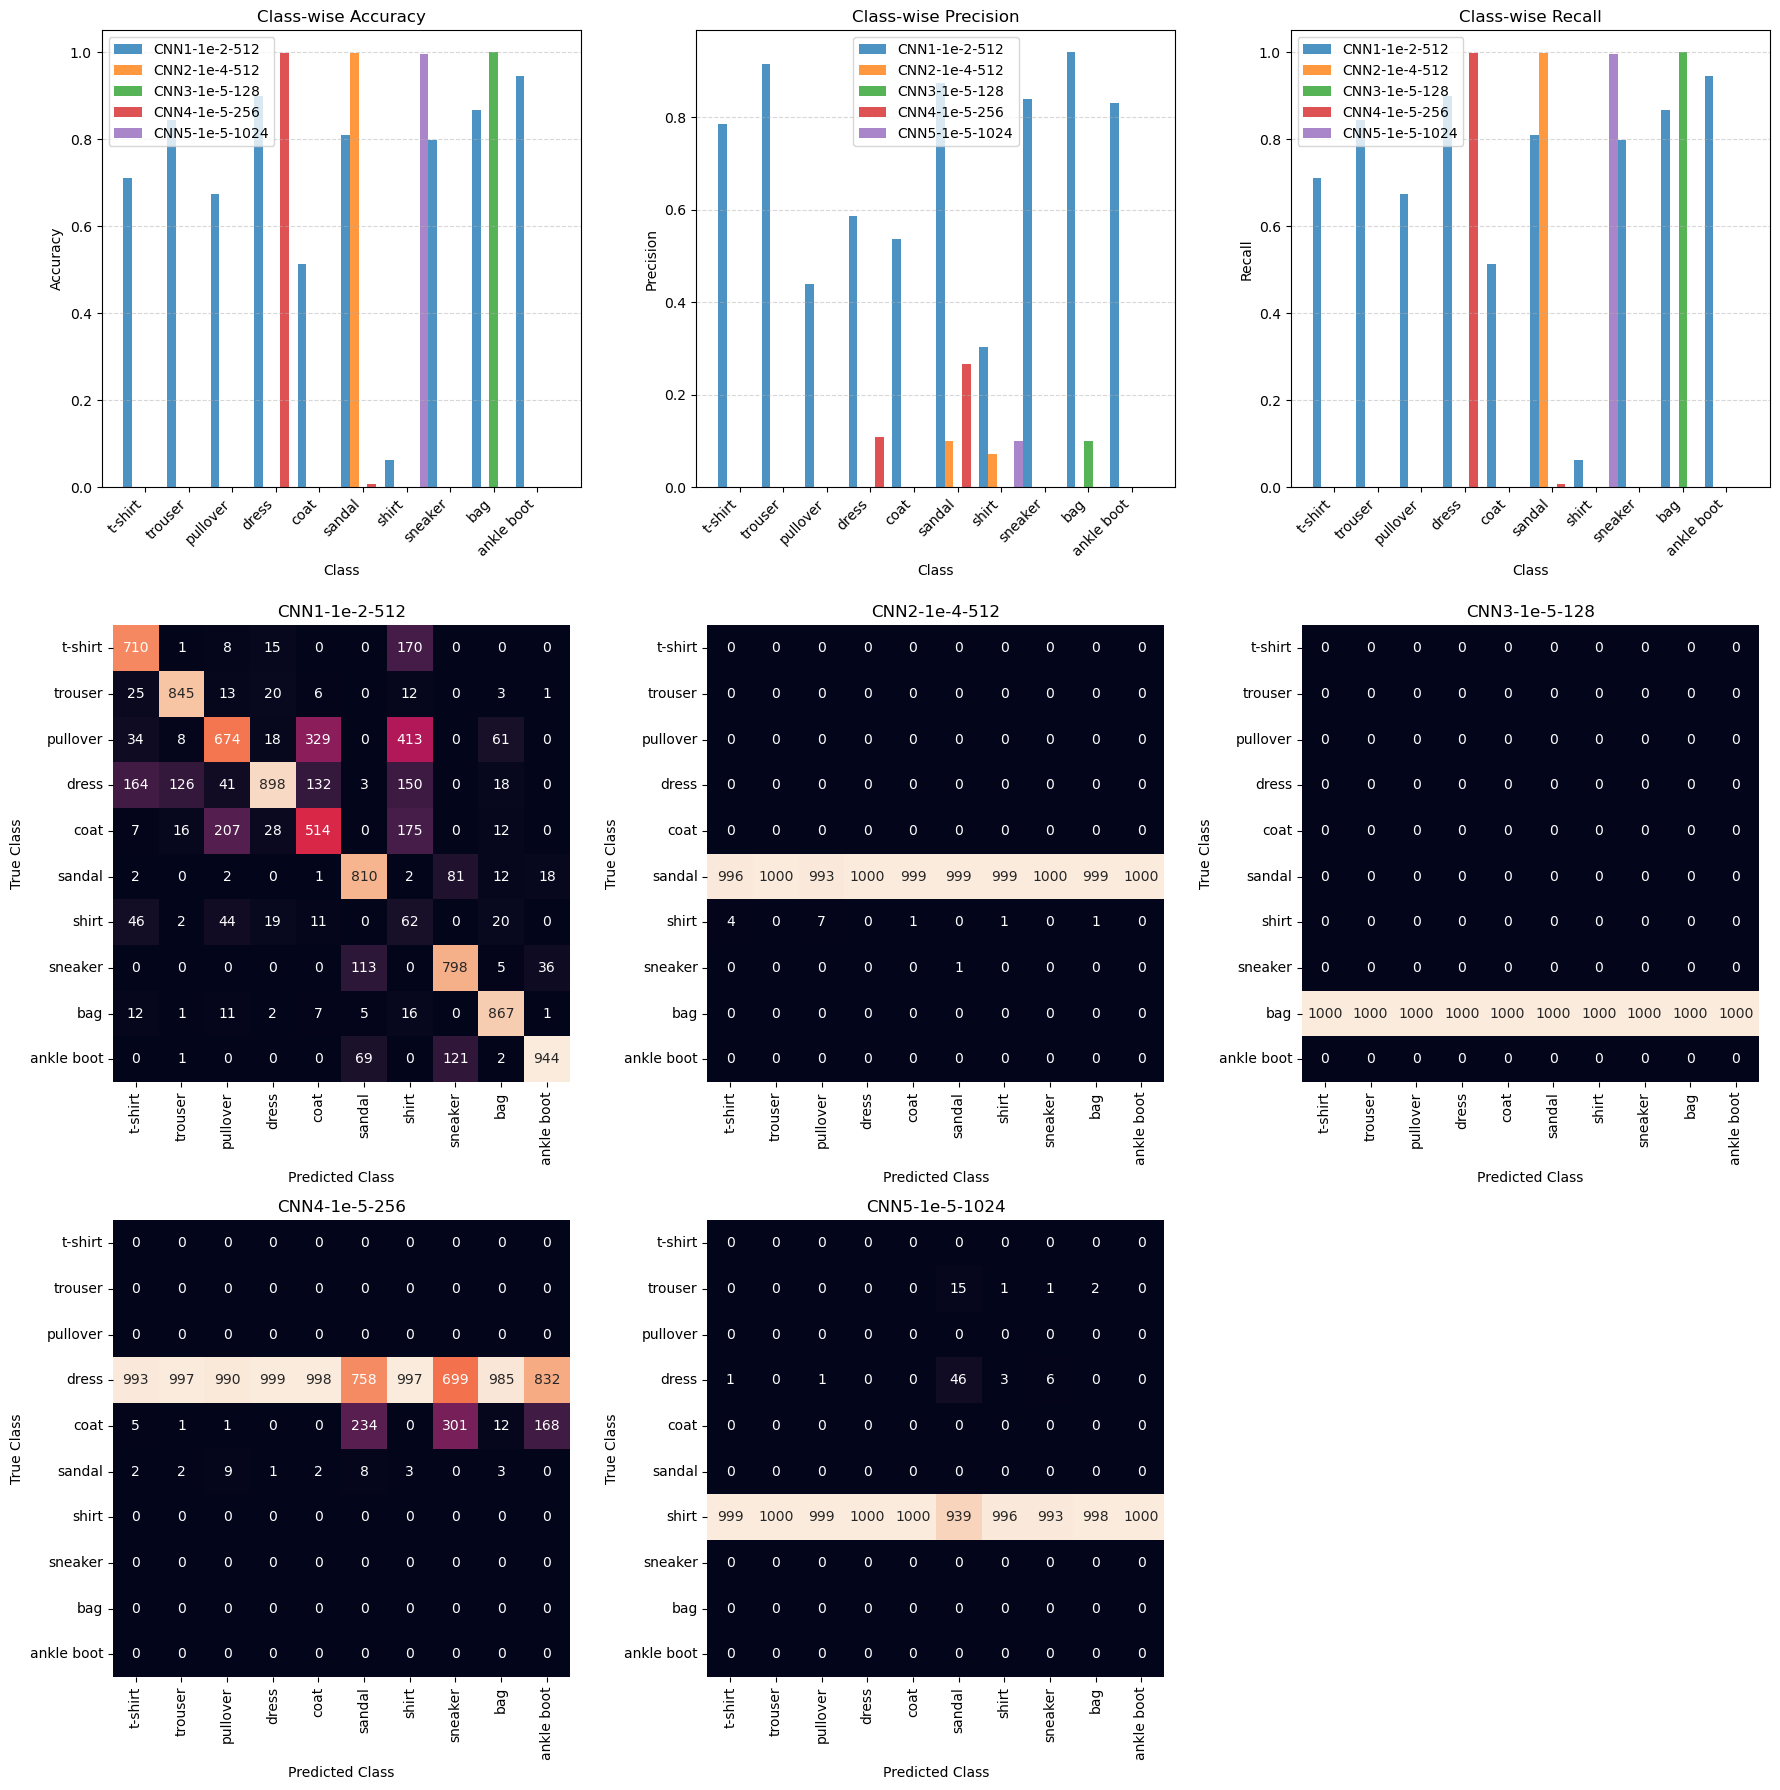

In [28]:
CNN_models = {
    'CNN1-1e-2-512': PyTorchTrainer.load('models/CNNBasic1.pkl'), 
    'CNN2-1e-4-512': PyTorchTrainer.load('models/CNNBasic2.pkl'),
    'CNN3-1e-5-128': PyTorchTrainer.load('models/CNNBasic3.pkl'), 
    'CNN4-1e-5-256': PyTorchTrainer.load('models/CNNBasic4.pkl'),
    'CNN5-1e-5-1024': PyTorchTrainer.load('models/CNNBasic5.pkl'),
    }

evaluate_overall_metrics(CNN_models)
evaluate(CNN_models)

## Comparing the different model architectures

---
**Task 9 (easy): Evaluation👩‍💻💡**
In the cell below:
1. Select the best performing MLP and CNN and update the cell below to store these models in the `MLPCNN_models`
 dictionary.
2. Use the  `evaluate_overall_metrics`
 function to visualize the overall performance of the models.
3. Use the `evaluate`
 function to visualize the class-wise performance of the models.


---

100%|██████████| 20/20 [00:00<00:00, 35.06it/s]


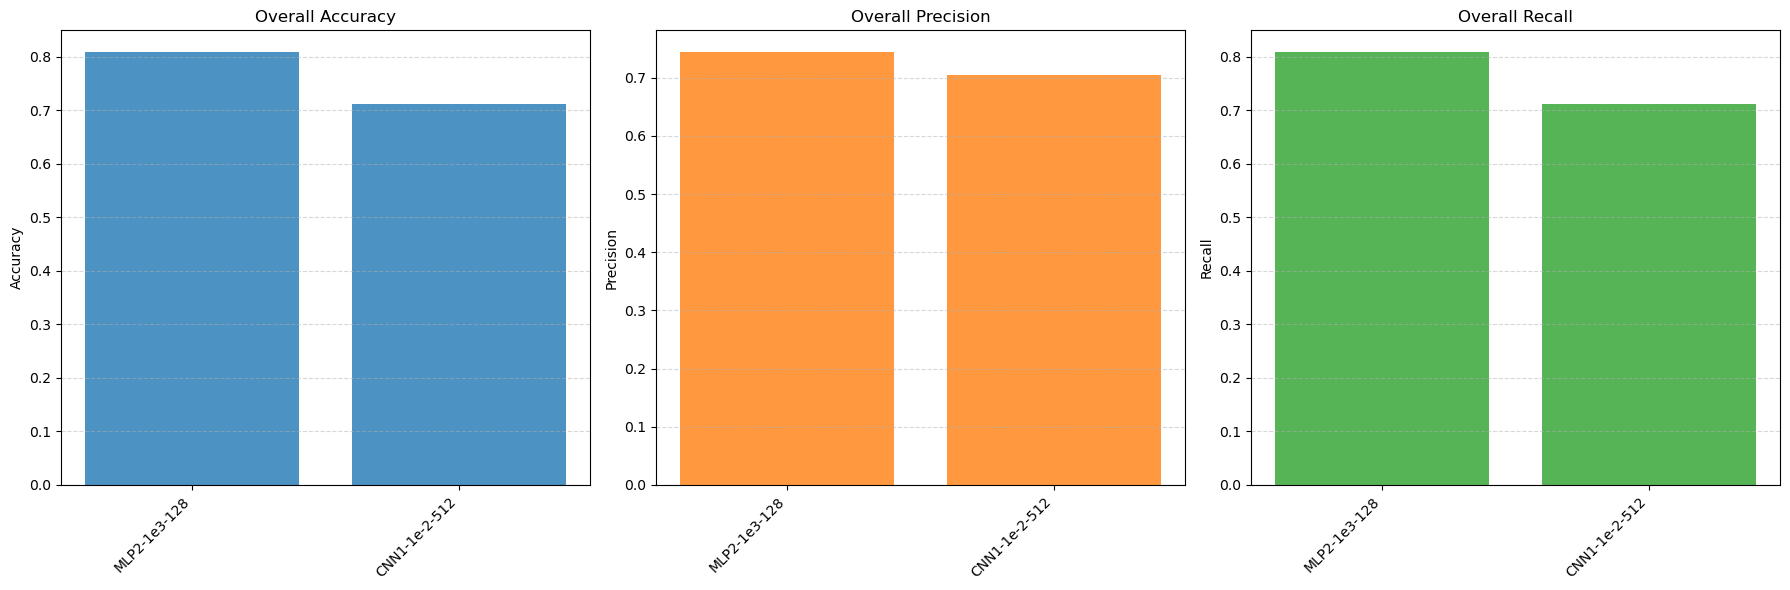

100%|██████████| 20/20 [00:00<00:00, 41.05it/s]


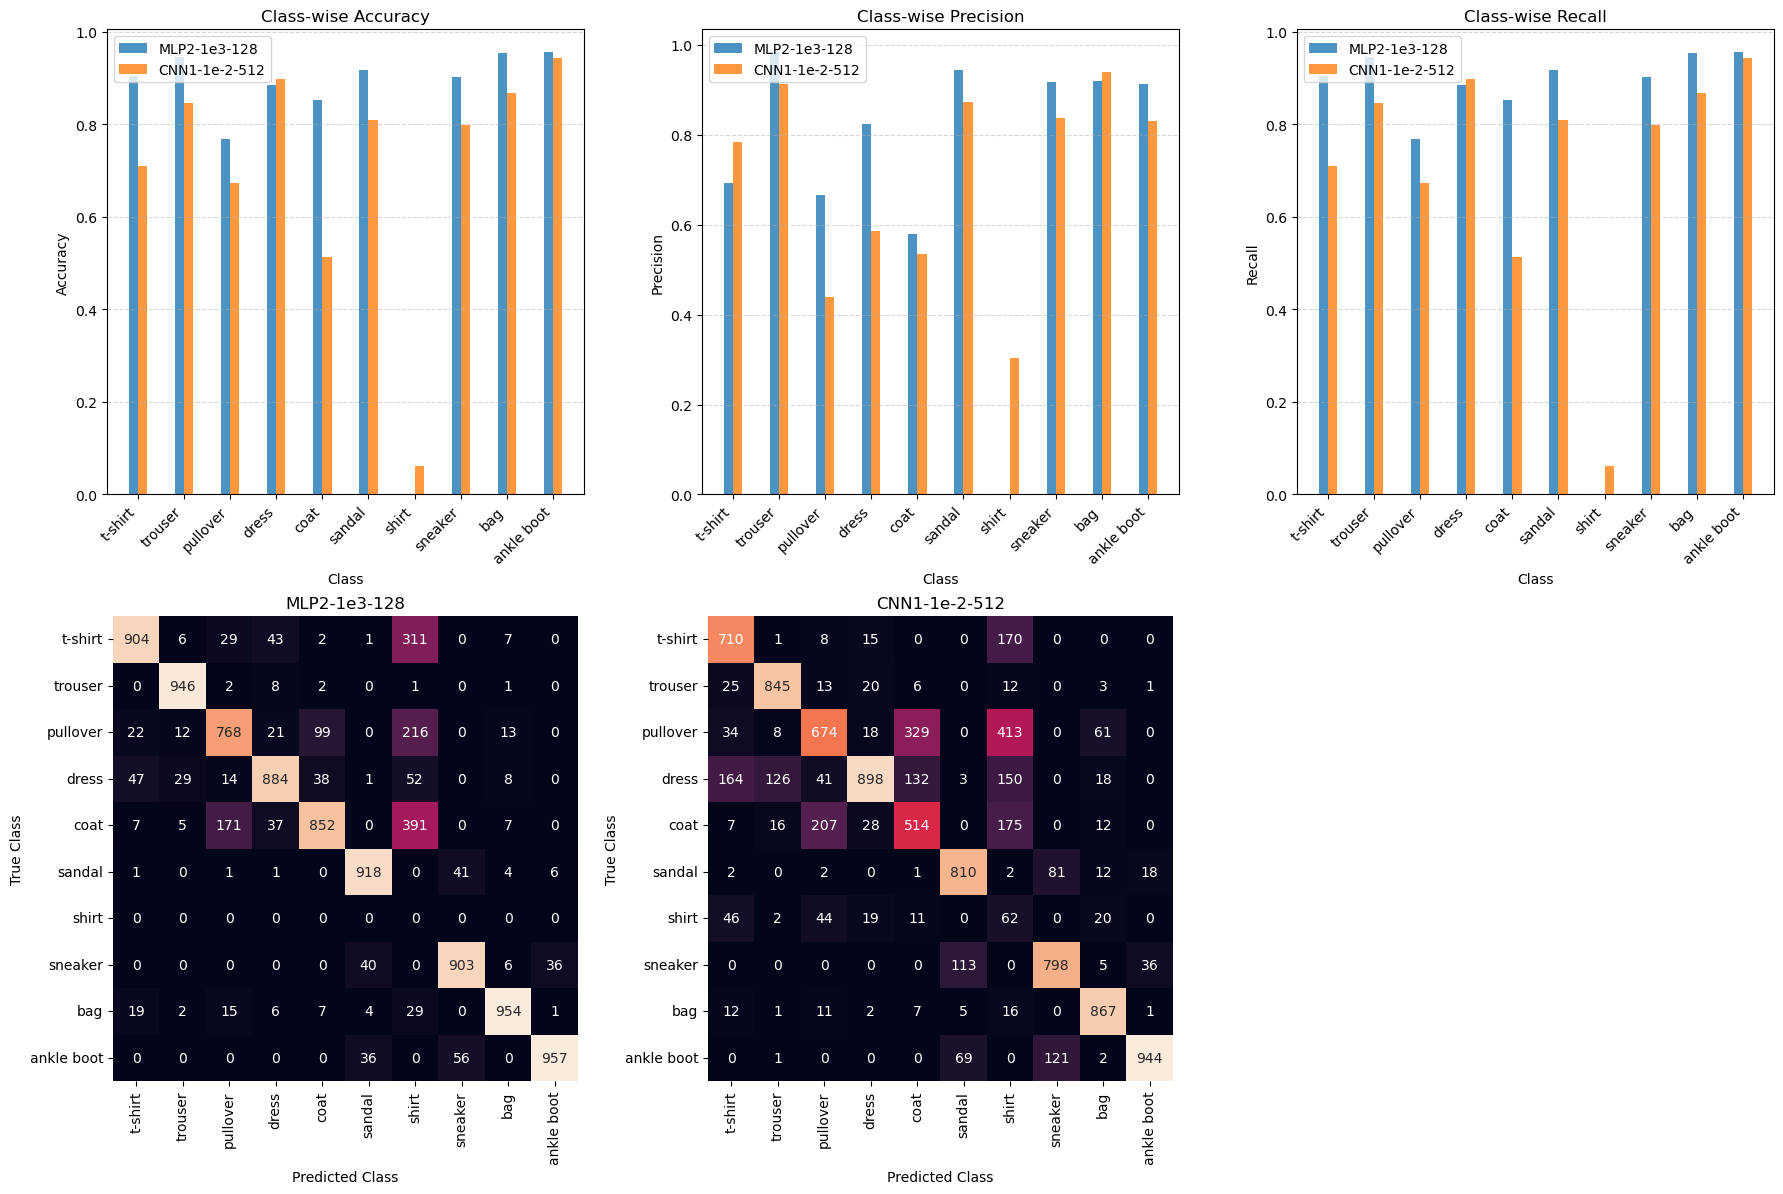

In [29]:
MLPCNN_models = {
    'MLP2-1e3-128': PyTorchTrainer.load('models/MLPBasic2.pkl'), 
    'CNN1-1e-2-512': PyTorchTrainer.load('models/CNNBasic1.pkl'),
    }

evaluate_overall_metrics(MLPCNN_models)
evaluate(MLPCNN_models)

Evaluate the performance of the different architectures.

---
**Task 10 (easy): Evaluation💡**
1. Training
    - Analyze the figures and explain the key characteristics of the training process for the models.


2. Metrics
    - Assess the performance of the models by examining the confusion matrices and comparing the MLP and CNN models in terms of accuracy, precision, and recall. Discuss the strengths and weaknesses of each model based on the metrics.




---

In [30]:
# 1. Training: 
"""
MLP:
Loss decreases steadily but slower compared to the CNN.
Training is fast (~17 seconds) due to the simple architecture.

CNN:
Loss decreases rapidly, showing better learning efficiency.
Training takes longer (~57 seconds) due to convolutional operations.
"""


# 2. Metrics:
"""
Performance Metrics
Overall Metrics:
Accuracy:
MLP: ~70%.
CNN: Slightly lower, also ~70%.
Precision:
MLP: ~70%.
CNN: Comparable, ~70%.
Recall:
MLP: Slightly higher recall (~70%) than CNN.
Class-Wise Metrics:
MLP:
Struggles with complex or visually similar classes like "shirt" and "pullover."
CNN:
Struggles with "shirt" and "coat," similar to the MLP, but able to find some shirts
Confusion Matrices:
MLP:
Higher misclassifications for classes like "shirt" and "pullover."
CNN:
Better class separation for distinct patterns but struggles similarly on ambiguous classes.
"""

'\nPerformance Metrics\nOverall Metrics:\nAccuracy:\nMLP: ~70%.\nCNN: Slightly lower, also ~70%.\nPrecision:\nMLP: ~70%.\nCNN: Comparable, ~70%.\nRecall:\nMLP: Slightly higher recall (~70%) than CNN.\nClass-Wise Metrics:\nMLP:\nStruggles with complex or visually similar classes like "shirt" and "pullover."\nCNN:\nStruggles with "shirt" and "coat," similar to the MLP, but able to find some shirts\nConfusion Matrices:\nMLP:\nHigher misclassifications for classes like "shirt" and "pullover."\nCNN:\nBetter class separation for distinct patterns but struggles similarly on ambiguous classes.\n'

## Modifying architectures
The next part of the exercise is about experimenting with the architecture of an NN such as _number of layers_, _number of perceptrons (nodes)_ and _kernel size_.
### MLP
The following task will add a hidden layer to the MLP model. 

---
**Task 11 (medium): Adding a hidden layer👩‍💻**
1. Locate the class `MLP_modified`
 in the `networks.py`
 file. The `MLP_modified`
 class is a copy of the `MLPBasic`
 and the following steps are about making changes in the architecture.
2. Modify the architecture by adding a new hidden layer with 256 nodes, by updating the constructor. Ensure that the number of input and output features match between the layers.
3. Update the `forward`
 function to ensure this new hidden layer is used in the predictions. 
4. Train the model by running the cell below.


---

training the network started
[Epoch 1]


100%|██████████| 94/94 [00:00<00:00, 271.13it/s]


[Validation] Epoch 1: acc: 0.6182, val_loss: 1.1587, train_acc: 0.5110
[Epoch 2]


100%|██████████| 94/94 [00:00<00:00, 271.45it/s]


[Validation] Epoch 2: acc: 0.6764, val_loss: 0.9789, train_acc: 0.5798
[Epoch 3]


100%|██████████| 94/94 [00:00<00:00, 274.15it/s]


... (11 outputs left out)

100%|██████████| 94/94 [00:00<00:00, 267.83it/s]


[Validation] Epoch 9: acc: 0.7185, val_loss: 0.7827, train_acc: 0.6733
[Epoch 10]


100%|██████████| 94/94 [00:00<00:00, 267.52it/s]


[Validation] Epoch 10: acc: 0.7188, val_loss: 0.7773, train_acc: 0.6774


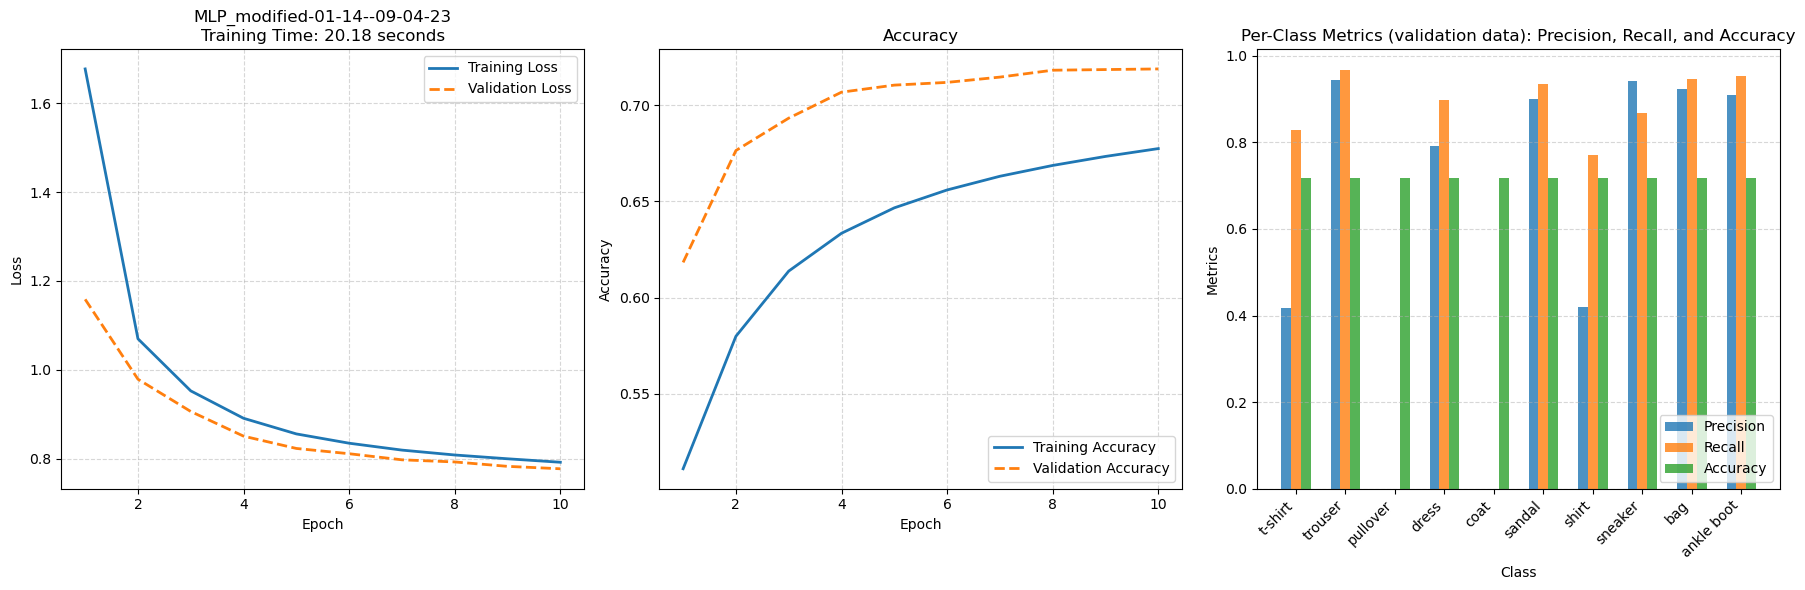

100%|██████████| 79/79 [00:00<00:00, 274.48it/s]

training and saving the network ended


In [31]:
train_pytorch_network(MLP_modified())


---
**Task 12 (easy): Compare performance💡**
1. Examine the training figures to identify and explain the characteristics of the model’s training process. 


---

In [32]:
# Loss decreases more sharply and converges earlier, with training and validation losses closely aligned.
# Accuracy increases rapidly and plateaus at a higher value compared to the baseline MLP.
# Lower loss and higher accuracy indicate improved learning and generalization.
# Much better at distinguishing between similar classes like "shirt" and "coat" due to additional hidden layers.
# Still sruggles with dress

Evaluate the modified MLP against the `MLPBasic()`


---
**Task 13 (easy): Compare architectures👩‍💻💡**
In the cell below:
1. Identify the best-performing `MLP`
 and `MLPModified`
 models based on the evaluation metrics. Update the cell below to store these selected models in the `modelsMLPModified`
 dictionary.
2. Use the `evaluate_overall_metrics`
 function to visualize the overall performance of the models.
3. Use the `evaluate`
 function to visualize the class-wise performance of the models.


---

In [33]:
MLPModified_model = {
    'MLP2-1e3-128': PyTorchTrainer.load('models/MLPBasic1.pkl'), 
    'MLP_mod1-1e3-128': PyTorchTrainer.load('models/MLP_mod1.pkl'), 
    'MLP_mod2-1e2-256': PyTorchTrainer.load('models/MLP_mod2.pkl'), 
    'MLP_mod3-512-hidden': PyTorchTrainer.load('models/MLP_mod3.pkl'),
    # Add more...
    }

evaluate_overall_metrics(MLPModified_model)
evaluate(MLPModified_model)

  0%|          | 0/79 [00:00<?, ?it/s]


AttributeError: 'MLP_modified' object has no attribute 'layer_3'


---
**Task 14 (easy): Compare performance💡**
1. Evaluate the performance of the models by analyzing the confusion matrices. Compare the MLP and CNN models in terms of key metrics such as accuracy, precision, and recall, and provide a detailed explanation of their relative strengths and weaknesses based on these metrics


---

In [0]:
# Write your reflections here...


---

**Task 15 (easy): Update architecture👩‍💻💡**
1. Change the number of hidden nodes to 512 (adjust the other layers accordingly). 
2. Rerun the cell above to train the new model. 
3. Include the new model in the dictionary. 
4. Evaluate the model and compare it with the others as in [Task 13](#CNN_mod).


---## Convolutional Neural Network
The following task will involve modifying the architechture of the CNN. 

**Hint**
- Recall that the kernel size influences the size of the output image. Specifically, for kernel size $k$, the output has dimensions $w-(k-1) \times h-(k-1)$ where $w$ is the width and $h$ is the height of an image. Adding a convolutional layer is consequently a bit more tricky than a linear layer because the dimensions between the layers need to match. You will likely need to debug the model a few times to get it right, therefor we encourage you to carefully examine the structure of the network before modifying it.
- Convolutional layers MAY be accompanied with a max pooling layer, but remember to use an activation function.
- The `max_pool2d`
 operation in the`forward`
 function halves the image resolution. 



---
**Task 16 (medium): Adding a convolutional layer👩‍💻**
1. Locate the class `CNN_modified()`
 in the `networks.py`
 file.
2. Examine the class to gain an overview of the network architecture. _Note that it is a copy of the CNNBasic() class_.
3. Add a new `Conv2d`
 layer to the `CNN_modified`
 class by decreasing the kernel size of the existing first layer and add the new layer as the second layer.


**Hint**
Use `tensor.size`
 to get the size of any tensor.

4. Update the `forward`
 method to ensure this new hidden layer is used in the predictions. 
5. Train the model by running the cell below.


---

In [ ]:
train_pytorch_network(CNN_modified())

training the network started
[Epoch 1]


  0%|          | 0/375 [00:00<?, ?it/s]


RuntimeError: mat1 and mat2 shapes cannot be multiplied (128x32 and 256x60)


---
**Task 17 (easy): Compare architectures👩‍💻💡**
1. Fill in the dictionary below with the best performing `CNNBasic()`
 model and the `CNNModified()`
.
2. Visualize the overall performance by running `evaluate_overall_metrics`
 function.
3. Visualize the class-wise performance by running the `evaluate`
 function.


---

100%|██████████| 20/20 [00:00<00:00, 45.22it/s]


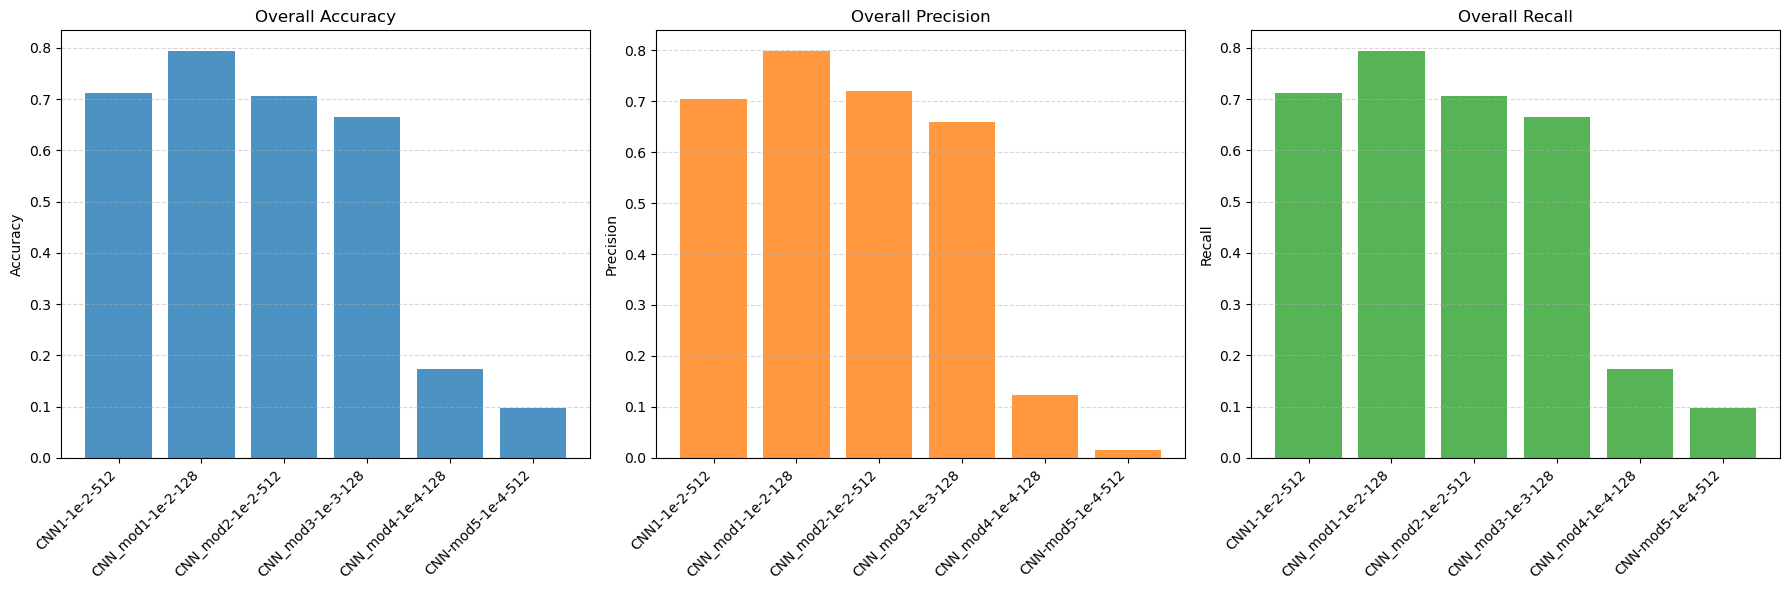

100%|██████████| 20/20 [00:00<00:00, 44.71it/s]


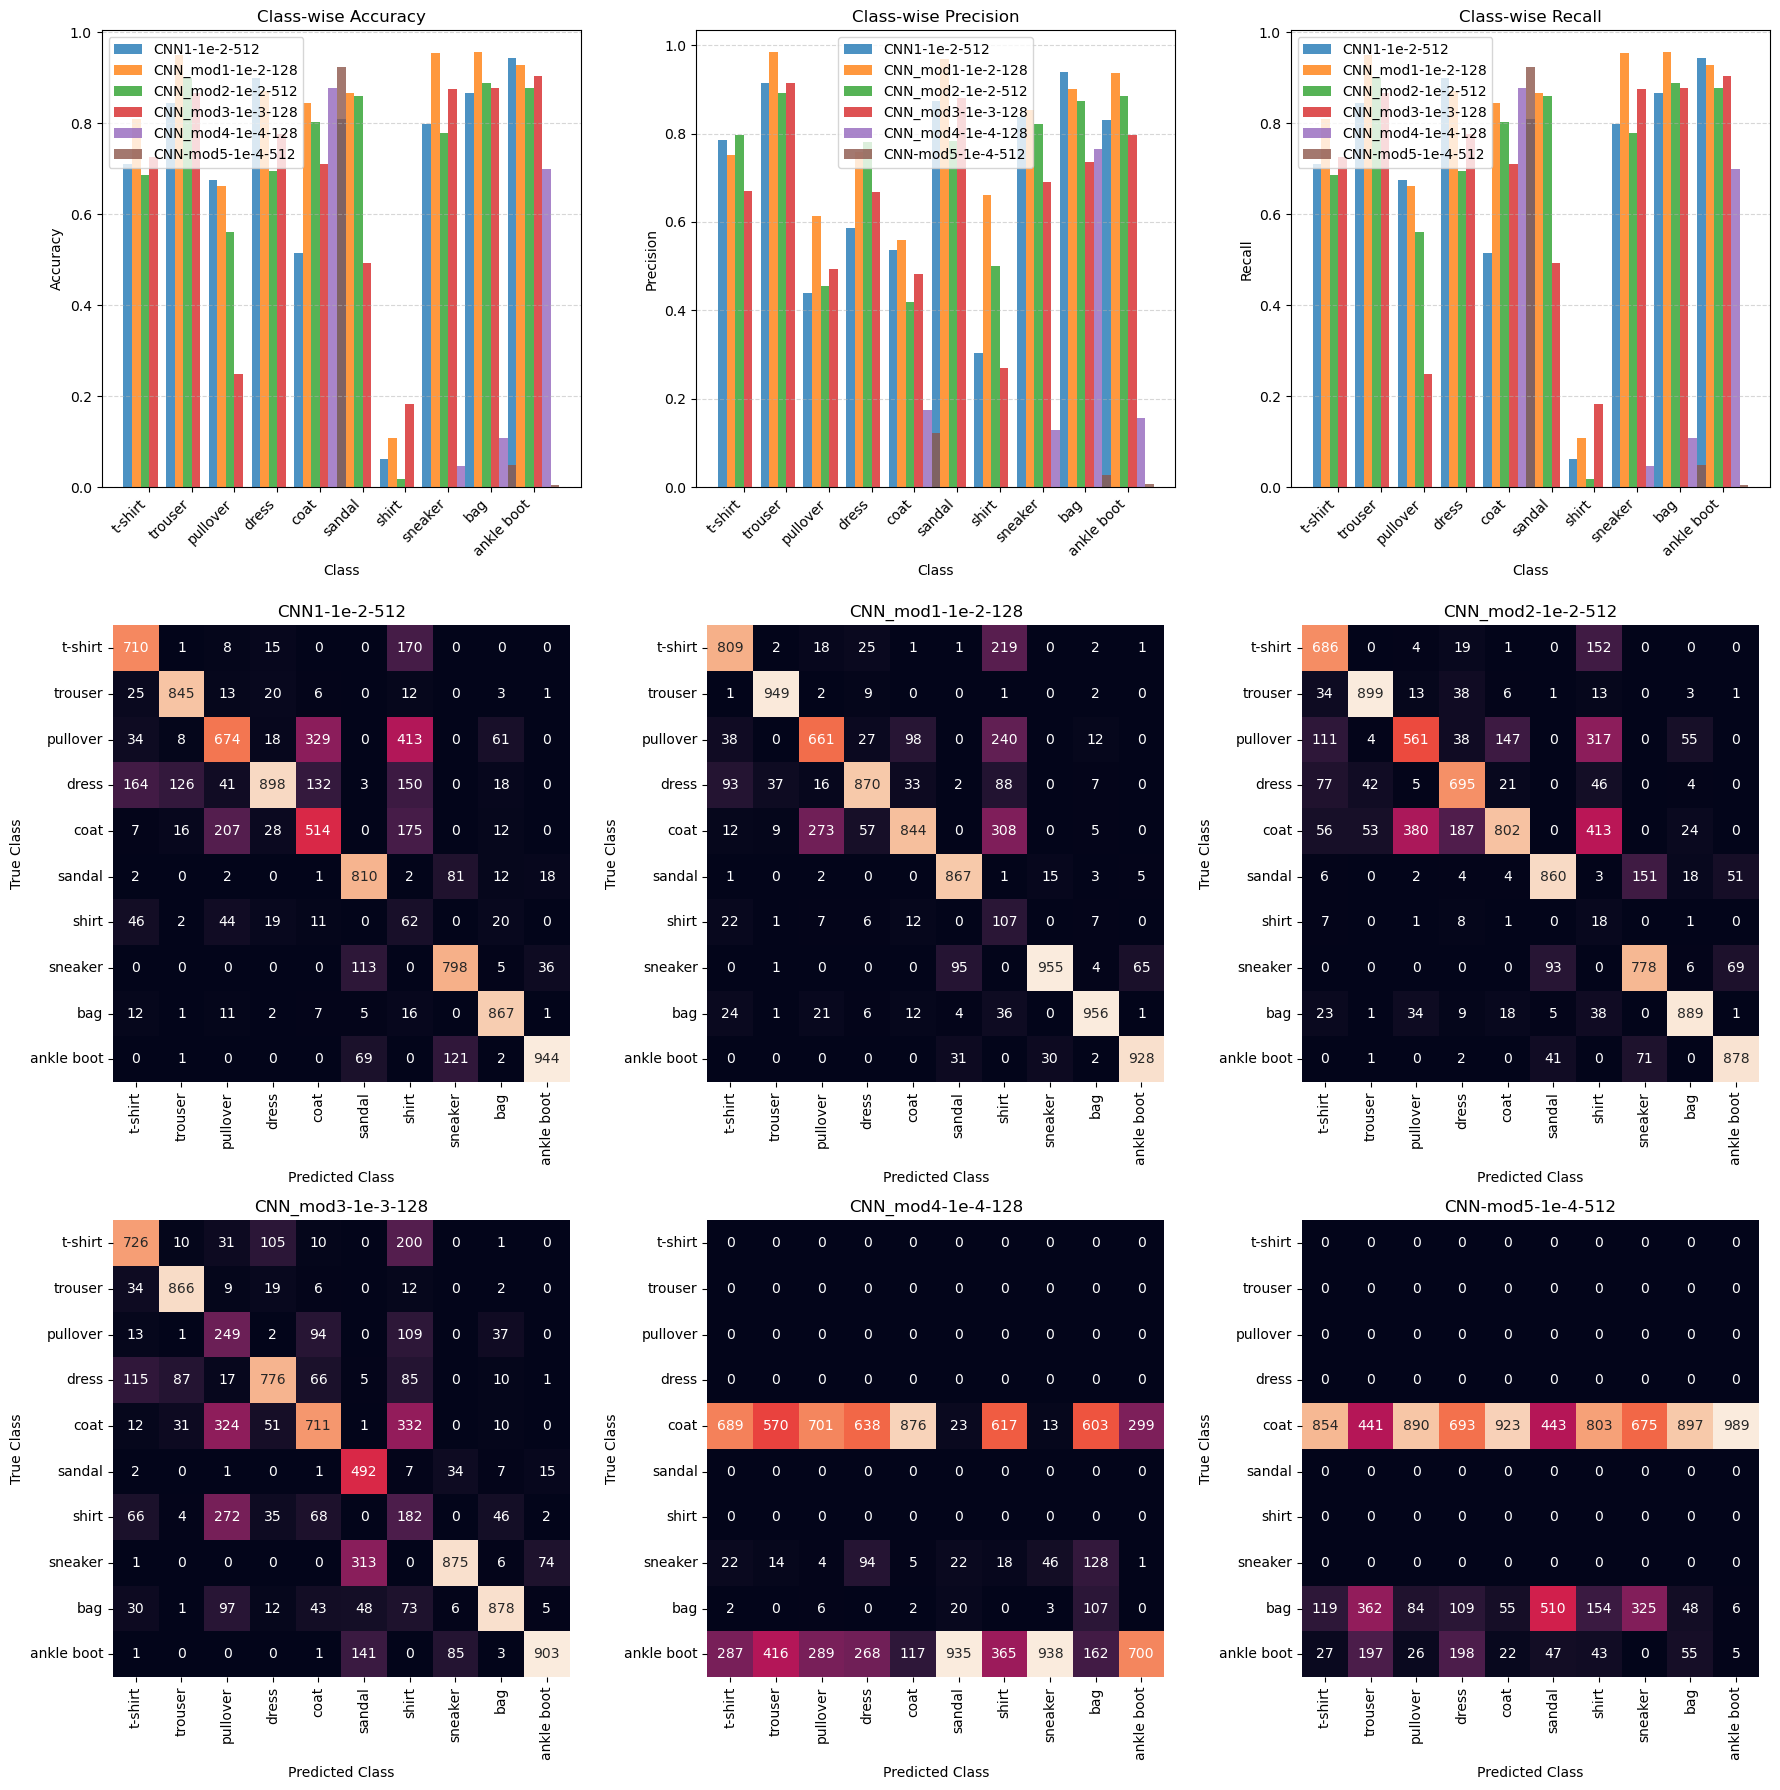

In [46]:
CNNModified_model = {
    'CNN1-1e-2-512': PyTorchTrainer.load('models/CNNBasic1.pkl'), 
    'CNN_mod1-1e-2-128': PyTorchTrainer.load('models/CNN_mod1.pkl'), 
    'CNN_mod2-1e-2-512': PyTorchTrainer.load('models/CNN_mod2.pkl'),
    'CNN_mod3-1e-3-128': PyTorchTrainer.load('models/CNN_mod3.pkl'),
    'CNN_mod4-1e-4-128': PyTorchTrainer.load('models/CNN_mod4.pkl'),
    'CNN-mod5-1e-4-512': PyTorchTrainer.load('models/CNN_mod5.pkl'),
    # Add more...
    }

evaluate_overall_metrics(CNNModified_model)
evaluate(CNNModified_model)


---
**Task 18 (medium): Compare architectures💡**
Evaluate the modified CNN against the `CNNBasic()`
 following the steps: 
1. During training:
    - Include the trained `CNNBasic()`
and the `CNNModified()`
 in the graphs (leave out the rest).
    - What patterns or trends do you observe in the loss and accuracy graphs and training time throughout training?


2. Update the dictionary below with the trained models and execute the cell. Compare the performance of the models, providing an analysis and explanation of the observed differences.

3. Change the kernel size and the number of kernels to achieve the best performing model, while avoiding overfitting. Run the cell above to train the new model. Include the new model in the dictionary, evaluate the model and compare it with the others.



---

In [0]:
# Write your reflections here...
"""
Small Kernel Size (e.g.,  3×3):
Captures local features (e.g., edges, corners, small patterns).
Effective for deep networks because multiple layers of small kernels can combine to capture larger features.

Large Kernel Size (e.g., 9×9):
Captures global features (e.g., larger textures or patterns).
Reduces the ability to focus on small, detailed features.
May lead to over-smoothing and loss of finer details.
"""

This exercise has briefly introduced some modifications that can improve the performance of a model. While this was just a brief introduction many more alterations can be performed. However, as noted, this easily becomes a time sink. The next task is optional and continues the introduction of possible alterations.

---
**Task 19 (hard): Additional improvements _(optional)_👩‍💻**
Change the activation functions, the number of hidden layers, and the training setup to achieve the best performing model. Notice, that a huge amount of time can be spent on fiddling with the models.

---